<a href="https://colab.research.google.com/github/jesicaroman17-cpu/demo-uv-202602/blob/main/Trabajo_Final_Riesgo_Crediticio_Proyecto_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introducción**

El riesgo crediticio es un aspecto fundamental para las entidades financieras, ya que permite evaluar la posibilidad de que un cliente presente dificultades para cumplir con sus obligaciones de pago. Una adecuada identificación de estos riesgos contribuye a mejorar los procesos de evaluación de solicitudes de crédito y a tomar decisiones financieras con mayor información.

En este proyecto se desarrollará un análisis de datos y un modelo de Machine Learning orientado a predecir el incumplimiento de las obligaciones crediticias de los clientes, utilizando información relacionada con sus características personales, situación económica, ingresos y condiciones del crédito.

Para llevar a cabo este análisis se utilizará el conjunto de datos `application_train.csv`, compuesto por 307.511 registros y 122 variables. La variable objetivo, denominada `TARGET`, permite identificar si un cliente presenta dificultades de pago (1) o si no presenta dificultades (0).

El desarrollo del proyecto comprenderá diferentes etapas. Inicialmente, se realizará un análisis exploratorio para conocer la estructura de los datos, identificar valores faltantes, estudiar la distribución de las variables y reconocer posibles valores atípicos. Posteriormente, se llevará a cabo un proceso de limpieza y preparación de la información, que incluirá la selección de variables relevantes, el tratamiento de datos faltantes, la creación de variables derivadas y la transformación de variables numéricas y categóricas.

Una vez preparada la información, se construirán y evaluarán tres modelos de clasificación: Regresión Logística, Random Forest y XGBoost. Su desempeño será comparado mediante métricas como Accuracy, Precision, Recall, F1-Score y ROC-AUC, con especial atención a la capacidad de identificar correctamente a los clientes que presentan incumplimiento crediticio.

Finalmente, se analizarán los resultados obtenidos para identificar las fortalezas y limitaciones de los modelos, considerando especialmente el desbalance existente entre clientes que cumplen y aquellos que presentan dificultades de pago. Esto permitirá establecer conclusiones sobre la utilidad de los modelos desarrollados para el análisis y la predicción del riesgo crediticio.

# **Objetivos**

## Objetivo general

Desarrollar y evaluar modelos de Machine Learning para predecir el incumplimiento crediticio de los clientes, a partir del análisis de sus características personales, económicas y financieras, con el propósito de identificar patrones asociados al riesgo de pago y comparar el desempeño de diferentes algoritmos de clasificación.

## Objetivos específicos

- Realizar un análisis exploratorio del conjunto de datos para comprender su estructura, identificar las variables disponibles y reconocer posibles problemas de calidad de la información.
- Seleccionar las variables más relevantes para el análisis del riesgo crediticio, considerando su relación con el problema de negocio.
- Aplicar técnicas de limpieza y preparación de datos, incluyendo el tratamiento de valores faltantes, valores atípicos y transformaciones de variables numéricas y categóricas.
- Construir modelos predictivos utilizando Regresión Logística, Random Forest y XGBoost.
- Evaluar y comparar el desempeño de los modelos mediante métricas de clasificación, prestando especial atención a la identificación de clientes con dificultades de pago.
- Analizar los resultados obtenidos y establecer conclusiones sobre el comportamiento, las ventajas y las limitaciones de los modelos evaluados.

#### **Carga de librerías y conjunto de datos**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RandomizedSearchCV

df = pd.read_csv('/content/application_train.csv')


#### **Dimensiones del dataset**

Este análisis permite conocer el tamaño de la base de datos. Es importante identificar cuántos registros (filas) y cuántas variables (columnas) serán analizadas durante el proyecto. Cada fila representa una solicitud de crédito y cada columna corresponde a una característica del cliente o del crédito.


In [ ]:
df.shape

(307511, 122)

In [ ]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


### **Estructura del dataset**

Se revisa la estructura del dataset para identificar:

 - Número total de observaciones.
 - Número total de variables.
 - Tipo de dato de cada variable.
 - Presencia preliminar de valores nulos.

Esta información será fundamental posteriormente para decidir qué transformaciones serán necesarias durante la preparación de los datos.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [ ]:
df.isnull().sum()

,0
SK_ID_CURR,0
TARGET,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
FLAG_OWN_CAR,0
...,...
AMT_REQ_CREDIT_BUREAU_DAY,41519
AMT_REQ_CREDIT_BUREAU_WEEK,41519
AMT_REQ_CREDIT_BUREAU_MON,41519
AMT_REQ_CREDIT_BUREAU_QRT,41519


In [ ]:
# porcentaje de nulos por variable
(df.isnull().mean()*100).sort_values(ascending=False)

,0
COMMONAREA_AVG,69.872297
COMMONAREA_MODE,69.872297
COMMONAREA_MEDI,69.872297
NONLIVINGAPARTMENTS_MEDI,69.432963
NONLIVINGAPARTMENTS_MODE,69.432963
...,...
FLAG_DOCUMENT_16,0.000000
FLAG_DOCUMENT_15,0.000000
FLAG_DOCUMENT_14,0.000000
FLAG_DOCUMENT_20,0.000000


El objetivo de este análisis es comprender cuántos clientes
presentan incumplimiento y cuántos no.

* TARGET = 0 -> Cliente sin dificultades de pago
* TARGET = 1 -> Cliente con dificultades de pago

Este paso es fundamental porque permite identificar si existe desbalance de clases, situación que puede afectar el desempeño de los modelos de clasificación.


In [ ]:
df['TARGET'].value_counts(normalize=True)

,proportion
TARGET,
0,0.919271
1,0.080729


Se calculan estadísticas descriptivas para comprender el comportamiento general de las variables numéricas. Entre los indicadores analizados se encuentran:
- Media
- Mediana
- Desviación estándar
- Valores mínimos y máximos
- Cuartiles

Este análisis permite detectar posibles valores atípicos, distribuciones sesgadas y comportamientos inusuales que deberán evaluarse en etapas posteriores.

In [ ]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


 Se calcula el número de valores únicos presentes en cada variable. Este análisis ayuda a identificar:

 - Variables binarias.
 - Variables categóricas.
 - Posibles identificadores únicos.
 - Variables con alta granularidad.

La cardinalidad será útil posteriormente para la selección de variables y para definir estrategias de codificación de variables categóricas.

In [ ]:
df.nunique().sort_values()

,0
TARGET,2
NAME_CONTRACT_TYPE,2
FLAG_OWN_REALTY,2
FLAG_OWN_CAR,2
FLAG_WORK_PHONE,2
...,...
DAYS_REGISTRATION,15688
DAYS_BIRTH,17460
EXT_SOURCE_1,114584
EXT_SOURCE_2,119831


In [ ]:
nulos = (
    df.isnull()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
      .reset_index()
)

nulos.columns = ['Variable', '% Nulos']

nulos.head(20)

,Variable,% Nulos
0,COMMONAREA_AVG,69.872297
1,COMMONAREA_MODE,69.872297
2,COMMONAREA_MEDI,69.872297
3,NONLIVINGAPARTMENTS_MEDI,69.432963
4,NONLIVINGAPARTMENTS_MODE,69.432963
5,NONLIVINGAPARTMENTS_AVG,69.432963
6,FONDKAPREMONT_MODE,68.386172
7,LIVINGAPARTMENTS_AVG,68.354953
8,LIVINGAPARTMENTS_MEDI,68.354953
9,LIVINGAPARTMENTS_MODE,68.354953


In [ ]:
cat_cols = df.select_dtypes(include='object')

cat_cols.columns.tolist()

['NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE',
 'EMERGENCYSTATE_MODE']

In [ ]:
num_cols = df.select_dtypes(include=['int64','float64'])

num_cols.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_AVG',
 'YEARS_BUILD_AVG',
 'COMMONAREA_AVG',
 'ELEVATORS_AVG',
 'ENTRANCES_AVG',
 'FLOORSMAX_AVG',
 'FLOORSMIN_AVG',
 'LANDAREA_AVG',
 'LIVINGAPARTMENTS_AVG',
 'LIVINGAREA_AVG',
 'NONLIVINGAPARTMENTS_AVG',
 'NONLIVINGAREA_AVG',
 'APARTMENTS_MODE',
 'BASEMENTAR

#### CONCLUSIONES:

El dataset analizado contiene 307.511 solicitudes de crédito y 122 variables, lo que proporciona una base de información suficientemente amplia para desarrollar modelos de clasificación orientados a la predicción del incumplimiento crediticio.

La variable objetivo (TARGET) presenta un comportamiento desbalanceado, ya que aproximadamente el 91,93 % de los clientes no presentan dificultades de pago, mientras que el 8,07 % corresponden a clientes con incumplimiento. Esta característica deberá considerarse posteriormente durante la evaluación de los modelos.

El análisis preliminar permitió identificar la coexistencia de variables numéricas y categóricas, así como la presencia de variables con altos porcentajes de valores faltantes, especialmente aquellas relacionadas con características físicas de la vivienda.

Debido a la cantidad de variables disponibles, se considera necesario realizar un proceso de selección de variables que permita enfocar el análisis en los atributos con mayor relevancia para el problema de negocio y con una mejor calidad de información.

## **Selección de Variables**

El dataset original contiene 122 variables. Sin embargo, no todas aportan el mismo valor para el análisis del riesgo crediticio. Trabajar con una gran cantidad de variables puede aumentar la complejidad del proyecto, dificultar la interpretación de los resultados e incorporar información con altos niveles de datos faltantes.

Por esta razón, antes de iniciar la etapa de limpieza y modelado, se realizará una selección inicial de variables basada en tres criterios:

* Relevancia para el negocio y el problema de riesgo crediticio.
* Calidad de la información disponible.
* Facilidad de interpretación de los resultados.

El objetivo es construir un conjunto de variables que permita comprender los factores asociados al incumplimiento y desarrollar modelos predictivos interpretables.

In [ ]:
variables_candidatas = [
    'TARGET',
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'CODE_GENDER',
    'DAYS_BIRTH',
    'CNT_CHILDREN',
    'CNT_FAM_MEMBERS',
    'NAME_FAMILY_STATUS',
    'NAME_EDUCATION_TYPE',
    'NAME_HOUSING_TYPE',
    'FLAG_OWN_REALTY',
    'FLAG_OWN_CAR',
    'DAYS_EMPLOYED',
    'NAME_INCOME_TYPE',
    'OCCUPATION_TYPE',
    'ORGANIZATION_TYPE',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

df[variables_candidatas].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   TARGET               307511 non-null  int64  
 1   AMT_INCOME_TOTAL     307511 non-null  float64
 2   AMT_CREDIT           307511 non-null  float64
 3   AMT_ANNUITY          307499 non-null  float64
 4   AMT_GOODS_PRICE      307233 non-null  float64
 5   CODE_GENDER          307511 non-null  object 
 6   DAYS_BIRTH           307511 non-null  int64  
 7   CNT_CHILDREN         307511 non-null  int64  
 8   CNT_FAM_MEMBERS      307509 non-null  float64
 9   NAME_FAMILY_STATUS   307511 non-null  object 
 10  NAME_EDUCATION_TYPE  307511 non-null  object 
 11  NAME_HOUSING_TYPE    307511 non-null  object 
 12  FLAG_OWN_REALTY      307511 non-null  object 
 13  FLAG_OWN_CAR         307511 non-null  object 
 14  DAYS_EMPLOYED        307511 non-null  int64  
 15  NAME_INCOME_TYPE 

In [ ]:
(df[variables_candidatas]
    .isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False))

,0
EXT_SOURCE_1,56.381073
OCCUPATION_TYPE,31.345545
EXT_SOURCE_3,19.825307
EXT_SOURCE_2,0.214626
AMT_GOODS_PRICE,0.090403
AMT_ANNUITY,0.003902
CNT_FAM_MEMBERS,0.000650
TARGET,0.000000
AMT_CREDIT,0.000000
AMT_INCOME_TOTAL,0.000000


In [ ]:
df[variables_candidatas].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TARGET,307511.0,NaN,NaN,NaN,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
AMT_INCOME_TOTAL,307511.0,NaN,NaN,NaN,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,NaN,NaN,NaN,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,NaN,NaN,NaN,27108.573909,14493.737315,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307233.0,NaN,NaN,NaN,538396.207429,369446.46054,40500.0,238500.0,450000.0,679500.0,4050000.0
CODE_GENDER,307511,3,F,202448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DAYS_BIRTH,307511.0,NaN,NaN,NaN,-16036.995067,4363.988632,-25229.0,-19682.0,-15750.0,-12413.0,-7489.0
CNT_CHILDREN,307511.0,NaN,NaN,NaN,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
CNT_FAM_MEMBERS,307509.0,NaN,NaN,NaN,2.152665,0.910682,1.0,2.0,2.0,3.0,20.0
NAME_FAMILY_STATUS,307511,6,Married,196432,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### **Hallazgo preliminar**

Durante el análisis descriptivo se identificó un comportamiento atípico en la variable DAYS_EMPLOYED. Mientras que la mayoría de los registros presentan valores coherentes con la antigüedad laboral de una persona, se observan casos con un valor de 365243 días, equivalente aproximadamente a 1000 años de empleo.

Dado que este valor no es realista desde el punto de vista del negocio, será necesario investigarlo y definir un tratamiento adecuado durante la fase de preparación de datos.

In [ ]:
tabla_variables = pd.DataFrame({
    'Variable': variables_candidatas})

tabla_variables['Tipo'] = tabla_variables['Variable'].apply(
    lambda x: df[x].dtype)

tabla_variables['%_Nulos'] = tabla_variables['Variable'].apply(
    lambda x: round(df[x].isnull().mean()*100,2))

tabla_variables

,Variable,Tipo,%_Nulos
0,TARGET,int64,0.00
1,AMT_INCOME_TOTAL,float64,0.00
2,AMT_CREDIT,float64,0.00
3,AMT_ANNUITY,float64,0.00
4,AMT_GOODS_PRICE,float64,0.09
5,CODE_GENDER,object,0.00
6,DAYS_BIRTH,int64,0.00
7,CNT_CHILDREN,int64,0.00
8,CNT_FAM_MEMBERS,float64,0.00
9,NAME_FAMILY_STATUS,object,0.00


#### **Selección inicial de variables**

Con base en el entendimiento del negocio, la calidad de los datos y la relevancia potencial para el problema de riesgo crediticio, se definió un conjunto inicial de 20 variables explicativas y una variable objetivo.

La selección busca representar diferentes dimensiones del solicitante, incluyendo aspectos financieros, demográficos, familiares, laborales, habitacionales y variables externas de evaluación del riesgo.

En esta etapa no se descartaron variables únicamente por la presencia de valores faltantes, dado que algunas de ellas podrían aportar capacidad predictiva relevante una vez se realice la fase de preparación de datos.

## **Preparación de los Datos**



In [ ]:
df['DAYS_EMPLOYED'].describe()

,DAYS_EMPLOYED
count,307511.000000
mean,63815.045904
std,141275.766519
min,-17912.000000
25%,-2760.000000
50%,-1213.000000
75%,-289.000000
max,365243.000000


In [ ]:
(df['DAYS_EMPLOYED'] == 365243).sum()

np.int64(55374)

In [ ]:
((df['DAYS_EMPLOYED'] == 365243).mean()*100)

np.float64(18.00716071945394)

In [ ]:
df.loc[df['DAYS_EMPLOYED'] == 365243, 'NAME_INCOME_TYPE'].value_counts()

,count
NAME_INCOME_TYPE,
Pensioner,55352
Unemployed,22


#### **Análisis de la variable DAYS_EMPLOYED**

Durante la exploración de la variable DAYS_EMPLOYED se identificó un valor atípico equivalente a 365243 días de antigüedad laboral. Inicialmente este valor podría interpretarse como un error de calidad de datos, debido a que representa aproximadamente 1000 años de empleo.

Sin embargo, al analizar la variable NAME_INCOME_TYPE se encontró que el 99,96 % de los registros con este valor corresponden a clientes clasificados como pensionados.

Lo anterior sugiere que dicho valor fue utilizado como un código especial para representar situaciones en las que la antigüedad laboral tradicional no resulta aplicable.

Por esta razón, antes de realizar cualquier transformación se deberá definir un tratamiento específico para estos registros, evitando interpretarlos como años reales de experiencia laboral.

#### **Tratamiento de valores especiales**

Durante el análisis de la variable DAYS_EMPLOYED se identificó el valor especial 365243, presente en aproximadamente el 18 % de los registros. Debido a que dicho valor no representa una antigüedad laboral real y se encuentra asociado principalmente a clientes pensionados, se decidió reemplazarlo por valores nulos (NaN) para facilitar su tratamiento posterior durante la fase de preparación de datos.

In [ ]:
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)

In [ ]:
(df[variables_candidatas]
 .isnull()
 .mean()*100
 ).sort_values(ascending=False)

,0
EXT_SOURCE_1,56.381073
OCCUPATION_TYPE,31.345545
EXT_SOURCE_3,19.825307
DAYS_EMPLOYED,18.007161
EXT_SOURCE_2,0.214626
AMT_GOODS_PRICE,0.090403
AMT_ANNUITY,0.003902
CNT_FAM_MEMBERS,0.000650
TARGET,0.000000
AMT_INCOME_TOTAL,0.000000


In [ ]:
correlaciones = (
    df[
        [
            'TARGET',
            'AMT_INCOME_TOTAL',
            'AMT_CREDIT',
            'AMT_ANNUITY',
            'AMT_GOODS_PRICE',
            'DAYS_BIRTH',
            'CNT_CHILDREN',
            'CNT_FAM_MEMBERS',
            'DAYS_EMPLOYED',
            'EXT_SOURCE_1',
            'EXT_SOURCE_2',
            'EXT_SOURCE_3'
        ]
    ]
    .corr(numeric_only=True)['TARGET']
    .sort_values(ascending=False))

correlaciones


,TARGET
TARGET,1.000000
DAYS_BIRTH,0.078239
DAYS_EMPLOYED,0.074958
CNT_CHILDREN,0.019187
CNT_FAM_MEMBERS,0.009308
AMT_INCOME_TOTAL,-0.003982
AMT_ANNUITY,-0.012817
AMT_CREDIT,-0.030369
AMT_GOODS_PRICE,-0.039645
EXT_SOURCE_1,-0.155317


#### **Análisis preliminar de correlación**

Se evaluó la relación lineal entre las variables numéricas seleccionadas y la variable objetivo (TARGET).

Las mayores correlaciones se observaron en las variables EXT_SOURCE_1, EXT_SOURCE_2 y EXT_SOURCE_3, las cuales presentan una relación negativa con el incumplimiento. Esto sugiere que valores más altos en estos indicadores externos están asociados con un menor riesgo crediticio.

Adicionalmente, variables relacionadas con la edad (DAYS_BIRTH) y la antigüedad laboral (DAYS_EMPLOYED) también muestran una relación observable con el riesgo de incumplimiento, por lo que se consideran variables relevantes para los análisis posteriores.

Las variables financieras presentan correlaciones lineales más bajas; sin embargo, se conservarán debido a su importancia desde el punto de vista del negocio y a su potencial aporte en la construcción de variables derivadas.

#### **Transformación de variables temporales**

Algunas variables del dataset almacenan información en unidades de días y mediante valores negativos, debido a que representan eventos ocurridos antes de la fecha de solicitud del crédito.

Con el fin de facilitar la interpretación de los resultados y mejorar la comprensión de las variables desde el punto de vista del negocio, se transformarán estas variables a años.

Particularmente, se calculan la edad del cliente y la antigüedad laboral aproximada utilizando las variables DAYS_BIRTH y DAYS_EMPLOYED, respectivamente.

In [ ]:
# Edad del cliente en años
df['AGE_YEARS'] = abs(df['DAYS_BIRTH']) / 365

# Antigüedad laboral en años
df['EMPLOYMENT_YEARS'] = abs(df['DAYS_EMPLOYED']) / 365

df[['DAYS_BIRTH','AGE_YEARS']].head()

,DAYS_BIRTH,AGE_YEARS
0,-9461,25.920548
1,-16765,45.931507
2,-19046,52.180822
3,-19005,52.068493
4,-19932,54.608219


In [ ]:
df[['AGE_YEARS','EMPLOYMENT_YEARS']].describe()

,AGE_YEARS,EMPLOYMENT_YEARS
count,307511.000000,252137.000000
mean,43.936973,6.531971
std,11.956133,6.406466
min,20.517808,0.000000
25%,34.008219,2.101370
50%,43.150685,4.515068
75%,53.923288,8.698630
max,69.120548,49.073973


In [ ]:
df.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED'],inplace=True)

In [ ]:
variables_candidatas = [
    'TARGET',
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'CODE_GENDER',
    'AGE_YEARS',
    'CNT_CHILDREN',
    'CNT_FAM_MEMBERS',
    'NAME_FAMILY_STATUS',
    'NAME_EDUCATION_TYPE',
    'NAME_HOUSING_TYPE',
    'FLAG_OWN_REALTY',
    'FLAG_OWN_CAR',
    'EMPLOYMENT_YEARS',
    'NAME_INCOME_TYPE',
    'OCCUPATION_TYPE',
    'ORGANIZATION_TYPE',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

#### **Estrategia de tratamiento de valores faltantes**

Durante la exploración de los datos se identificaron variables con diferentes niveles de valores faltantes. Debido a que las variables seleccionadas presentan características distintas (numéricas y categóricas), se definió una estrategia de imputación específica para cada caso.

Para las variables numéricas se utilizará la mediana, ya que es una medida robusta frente a valores extremos y distribuciones asimétricas.

Para las variables categóricas se creará una categoría denominada "No informado", permitiendo conservar los registros y diferenciando explícitamente los casos donde la información no se encuentra disponible.

Esta estrategia permite maximizar el aprovechamiento de los datos sin eliminar observaciones de manera innecesaria.

In [ ]:
# Imputación de variables numéricas
variables_numericas_nulos = [
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3',
    'EMPLOYMENT_YEARS',
    'AMT_GOODS_PRICE',
    'AMT_ANNUITY',
    'CNT_FAM_MEMBERS'
]

for columna in variables_numericas_nulos:
    df[columna] = df[columna].fillna(df[columna].median())

In [ ]:
#Imputación de variables categóricas
df['OCCUPATION_TYPE'] = (df['OCCUPATION_TYPE'].fillna('No informado'))

In [ ]:
# Validación

(df[variables_candidatas].isnull().sum().sort_values(ascending=False))

,0
TARGET,0
AMT_INCOME_TOTAL,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
CODE_GENDER,0
AGE_YEARS,0
CNT_CHILDREN,0
CNT_FAM_MEMBERS,0
NAME_FAMILY_STATUS,0


#### **Conclusiones de la preparación de los datos**

Durante la fase de preparación se identificaron y corrigieron diferentes situaciones relacionadas con la calidad de los datos.

Se detectó un valor especial en la variable DAYS_EMPLOYED (365243) que representaba principalmente clientes pensionados y no una antigüedad laboral real. Dicho valor fue tratado como dato faltante para evitar interpretaciones incorrectas.

Posteriormente se transformaron las variables temporales a unidades más comprensibles para el negocio mediante la creación de las variables AGE_YEARS y EMPLOYMENT_YEARS, facilitando la interpretación de los resultados.

Finalmente, se definió una estrategia de imputación para las variables que presentaban valores faltantes, utilizando la mediana para variables numéricas y una categoría específica para variables categóricas. Tras este proceso, las variables seleccionadas quedaron listas para las etapas posteriores de análisis y modelado.

## **Análisis Exploratorio de Datos (EDA)**

Una vez completadas las etapas de comprensión, selección y preparación de los datos, se realiza el análisis exploratorio con el objetivo de identificar patrones, tendencias y relaciones entre las variables seleccionadas y el incumplimiento crediticio.

Los análisis realizados estarán orientados a responder preguntas de negocio relacionadas con la edad, los ingresos, la experiencia laboral, la educación y otras características relevantes de los solicitantes.

#### **Análisis de la edad de los solicitantes**

La edad es una de las variables demográficas más utilizadas en los modelos de riesgo crediticio. La experiencia financiera, la estabilidad laboral y la capacidad de generación de ingresos suelen variar entre diferentes grupos de edad.

Por esta razón, se analiza si existen diferencias entre la edad de los clientes que presentan incumplimiento y aquellos que cumplen adecuadamente con sus obligaciones financieras.

In [ ]:
# Análisis de la edad de los solicitantes
df.groupby('TARGET')['AGE_YEARS'].describe()

,count,mean,std,min,25%,50%,75%,max
TARGET,,,,,,,,
0,282686.0,44.214182,11.956715,20.517808,34.345205,43.498630,54.229452,69.120548
1,24825.0,40.780351,11.487245,21.035616,31.221918,39.128767,49.416438,68.953425


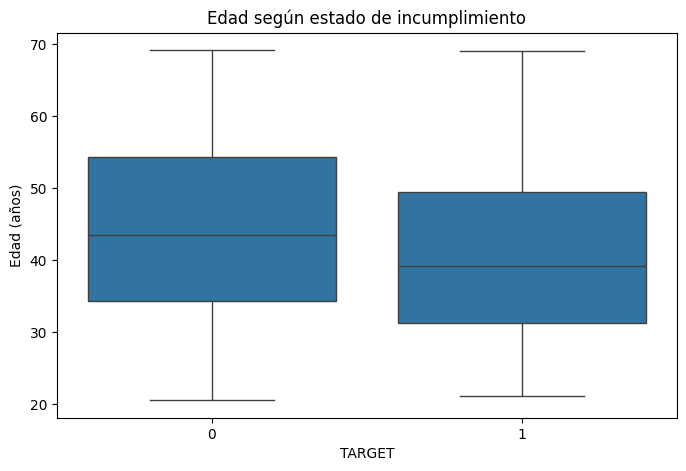

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='TARGET',
    y='AGE_YEARS'
)

plt.title('Edad según estado de incumplimiento')
plt.xlabel('TARGET')
plt.ylabel('Edad (años)')

plt.show()

Los clientes sin incumplimiento presentan una edad promedio de 44,21 años, mientras que los clientes con incumplimiento tienen una edad promedio de 40,78 años. Esta diferencia también se observa en la mediana y en la distribución presentada en el boxplot.

Los resultados sugieren que los clientes más jóvenes tienden a presentar un mayor riesgo de incumplimiento en comparación con los clientes de mayor edad. Sin embargo, la edad por sí sola no explica completamente el comportamiento de pago, por lo que debe analizarse conjuntamente con otras variables financieras, laborales y demográficas.

#### **Análisis de los ingresos de los solicitantes**

La capacidad de pago es uno de los factores más relevantes en la evaluación del riesgo crediticio. En términos generales, se espera que clientes con mayores ingresos tengan una mayor capacidad para cumplir sus obligaciones financieras.

Por esta razón, se analiza la distribución de los ingresos y su relación con el incumplimiento crediticio.

In [ ]:
df.groupby('TARGET')['AMT_INCOME_TOTAL'].describe()

,count,mean,std,min,25%,50%,75%,max
TARGET,,,,,,,,
0,282686.0,169077.722266,110476.268524,25650.0,112500.0,148500.0,202500.0,18000090.0
1,24825.0,165611.760906,746676.959440,25650.0,112500.0,135000.0,202500.0,117000000.0


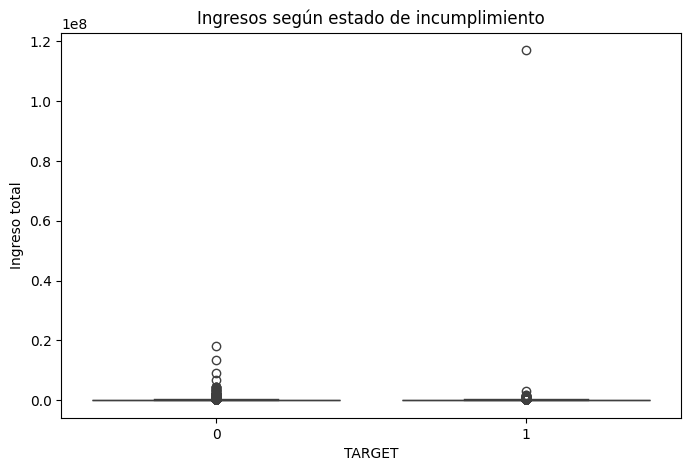

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='TARGET',
    y='AMT_INCOME_TOTAL'
)

plt.title('Ingresos según estado de incumplimiento')
plt.xlabel('TARGET')
plt.ylabel('Ingreso total')

plt.show()

#### **Hallazgos**

La distribución de ingresos presenta una alta dispersión y la presencia de valores extremos, situación que puede observarse tanto en los estadísticos descriptivos como en el boxplot.

Aunque las diferencias entre las medias de ambos grupos son relativamente pequeñas, la mediana de ingresos de los clientes que presentan incumplimiento es inferior a la observada en los clientes que cumplen sus obligaciones financieras.

Este resultado sugiere que menores niveles de ingreso podrían estar asociados con un mayor riesgo de incumplimiento. Sin embargo, la presencia de valores extremos dificulta la visualización de la distribución y deberá considerarse en análisis posteriores.

#### **Analisis de la antiguedad laboral**

Desde la perspectiva financiera, la estabilidad laboral suele estar asociada con una mayor capacidad para generar ingresos de manera constante y cumplir los compromisos adquiridos. Por esta razón, resulta relevante analizar si existen diferencias en la experiencia laboral entre los clientes que incumplen y aquellos que mantienen un buen comportamiento de pago.

In [ ]:
df.groupby('TARGET')['EMPLOYMENT_YEARS'].describe()

,count,mean,std,min,25%,50%,75%,max
TARGET,,,,,,,,
0,282686.0,6.278687,5.926682,0.0,2.649315,4.515068,7.706849,49.073973
1,24825.0,4.917300,4.755122,0.0,1.854795,3.994521,5.906849,44.024658


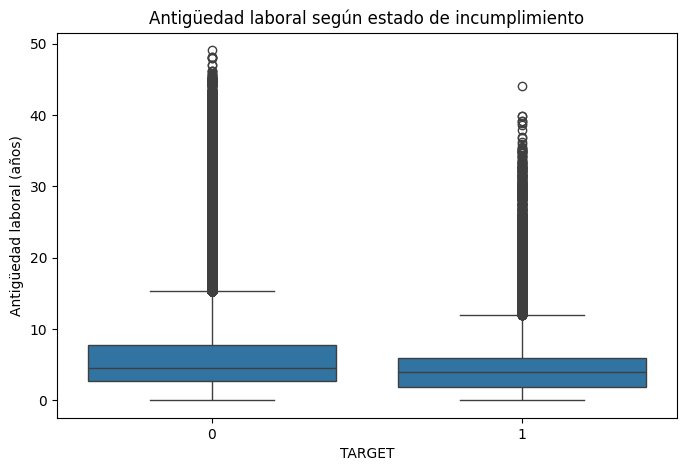

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='TARGET',
    y='EMPLOYMENT_YEARS'
)

plt.title('Antigüedad laboral según estado de incumplimiento')
plt.xlabel('TARGET')
plt.ylabel('Antigüedad laboral (años)')

plt.show()

#### **Hallazgos**

Se observó que los clientes que presentan incumplimiento poseen una menor antiguedad laboral en comparación con aquellos que cumplen adecuadamente sus obligaciones financieras.

La antiguedad laboral promedio de los clientes sin incumplimiento es de aproximadamente 6,28 años, mientras que para los clientes incumplidos es de 4,92 años. Esta diferencia también se evidencia en la mediana y en la distribución observada en el boxplot.

Los resultados sugieren que una mayor estabilidad laboral podría estar asociada con un menor riesgo crediticio, dado que los clientes con trayectorias laborales más largas tienden a presentar mejores comportamientos de pago.

#### **Análisis del nivel educativo**

El nivel educativo suele estar relacionado con aspectos como la empleabilidad, la estabilidad laboral y el nivel de ingresos. Por esta razón, resulta relevante analizar si existen diferencias en el comportamiento crediticio según el nivel de formación de los solicitantes.

Para ello se calculará la tasa de incumplimiento de cada categoría educativa con el fin de identificar cuáles grupos presentan mayor o menor riesgo.

In [ ]:
educacion_riesgo = (df.groupby('NAME_EDUCATION_TYPE')['TARGET'].mean().sort_values(ascending=False)* 100)
educacion_riesgo

,TARGET
NAME_EDUCATION_TYPE,
Lower secondary,10.927673
Secondary / secondary special,8.939929
Incomplete higher,8.484966
Higher education,5.355115
Academic degree,1.829268


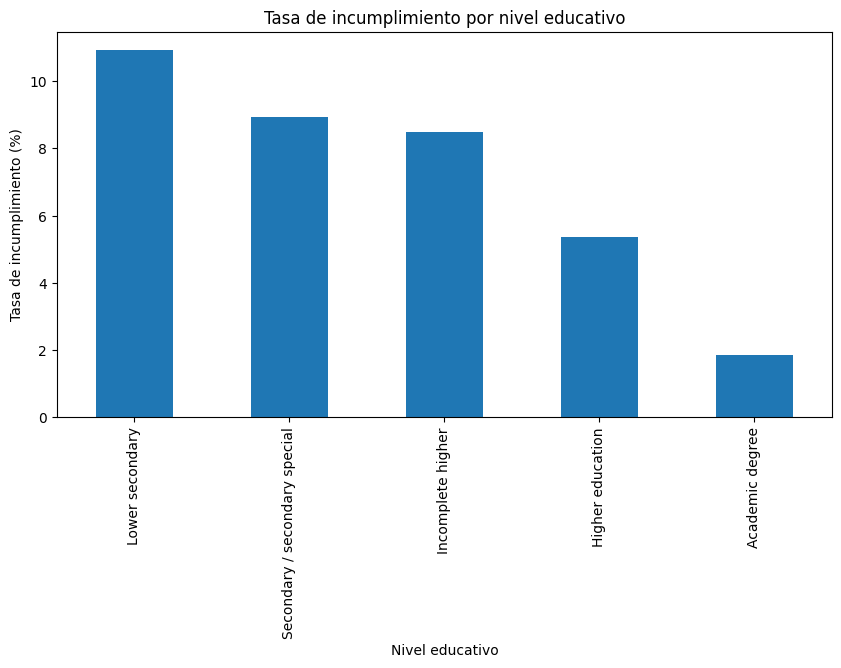

In [ ]:
plt.figure(figsize=(10,5))

educacion_riesgo.plot(kind='bar')

plt.title('Tasa de incumplimiento por nivel educativo')
plt.xlabel('Nivel educativo')
plt.ylabel('Tasa de incumplimiento (%)')

plt.show()

#### **Hallazgos**

El análisis evidencia una relación clara entre el nivel educativo y la tasa de incumplimiento crediticio.

Los clientes con menores niveles de educación presentan las tasas de incumplimiento más elevadas, mientras que los clientes con formación universitaria y grados académicos avanzados muestran niveles considerablemente inferiores de riesgo.

Particularmente, los clientes con educación secundaria básica presentan una tasa de incumplimiento cercana al 11%, mientras que los clientes con grado académico registran una tasa inferior al 2%.

Estos resultados sugieren que el nivel educativo constituye una variable relevante para la caracterización del riesgo crediticio, posiblemente debido a su relación con factores como la estabilidad laboral, el nivel de ingresos y las oportunidades económicas de los solicitantes.

#### **Análisis del tipo de ingreso**



In [ ]:
income_riesgo = (df.groupby('NAME_INCOME_TYPE')['TARGET'].mean().sort_values(ascending=False)* 100)
income_riesgo

,TARGET
NAME_INCOME_TYPE,
Maternity leave,40.000000
Unemployed,36.363636
Working,9.588472
Commercial associate,7.484257
State servant,5.754965
Pensioner,5.386366
Businessman,0.000000
Student,0.000000


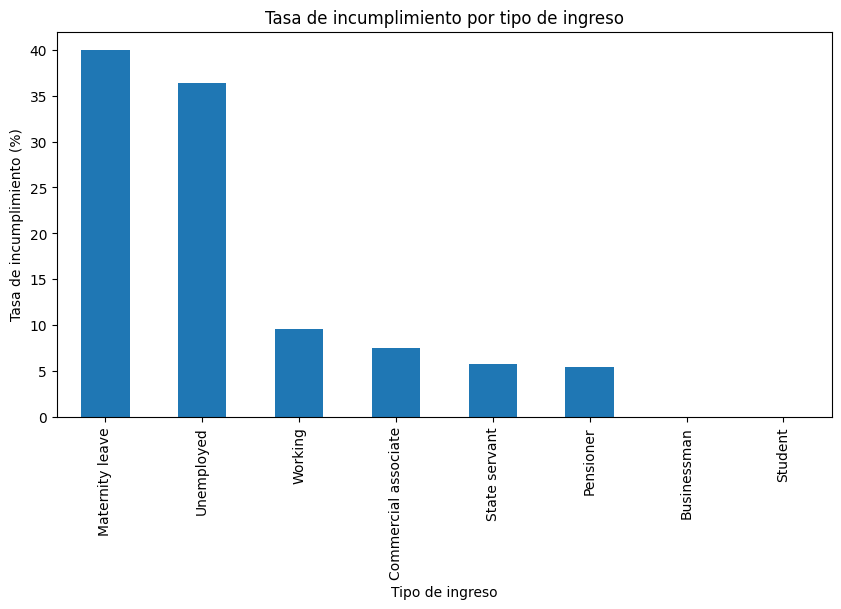

In [ ]:
plt.figure(figsize=(10,5))

income_riesgo.plot(kind='bar')

plt.title('Tasa de incumplimiento por tipo de ingreso')
plt.xlabel('Tipo de ingreso')
plt.ylabel('Tasa de incumplimiento (%)')

plt.show()

In [ ]:
df['NAME_INCOME_TYPE'].value_counts()

,count
NAME_INCOME_TYPE,
Working,158774
Commercial associate,71617
Pensioner,55362
State servant,21703
Unemployed,22
Student,18
Businessman,10
Maternity leave,5


#### **Hallazgos**

Inicialmente se identificaron algunas categorías con tasas de incumplimiento extremadamente altas. Sin embargo, al analizar el número de observaciones se encontró que categorías como Maternity leave, Unemployed, Student y Businessman contienen muy pocos registros, por lo que sus resultados no son representativos de la población general.

Considerando únicamente las categorías con una cantidad significativa de observaciones, se observa que los trabajadores activos presentan la tasa de incumplimiento más alta (9,59%), mientras que pensionados (5,39%) y funcionarios públicos (5,75%) presentan niveles de riesgo considerablemente menores.

Estos resultados sugieren que la estabilidad de la fuente de ingresos podría estar asociada con un menor riesgo crediticio, constituyéndose como un factor relevante para la evaluación de los solicitantes.

#### **Análisis de los indicadores externos de riesgo**

El dataset incluye las variables EXT_SOURCE_1, EXT_SOURCE_2 y EXT_SOURCE_3, las cuales corresponden a indicadores externos utilizados por la entidad financiera para complementar la evaluación crediticia de los solicitantes.

Aunque la metodología exacta de construcción de estos indicadores no se encuentra disponible, análisis previos mostraron que estas variables presentan las mayores correlaciones con la variable objetivo (TARGET), por lo que resulta relevante estudiar su comportamiento.

Inicialmente se analizará la variable EXT_SOURCE_2, debido a que presenta una menor proporción de valores faltantes respecto a los otros indicadores externos.

In [ ]:
df.groupby('TARGET')['EXT_SOURCE_2'].describe()

,count,mean,std,min,25%,50%,75%,max
TARGET,,,,,,,,
0,282686.0,0.52357,0.186087,8.173617e-08,0.410339,0.573402,0.667521,0.85500
1,24825.0,0.41126,0.213002,5.002109e-06,0.239084,0.441076,0.593937,0.81187


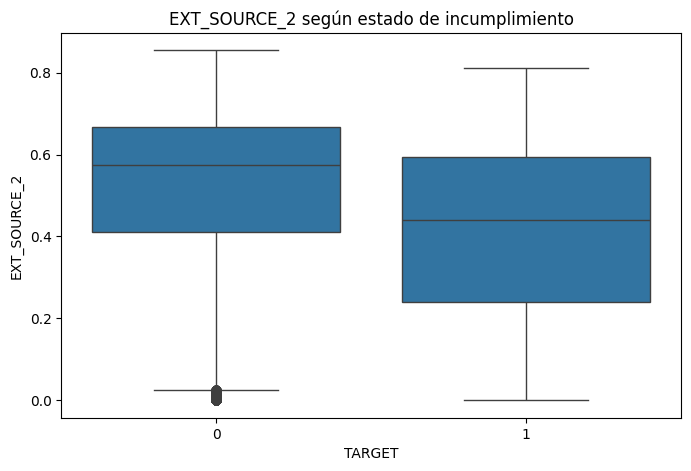

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='TARGET',
    y='EXT_SOURCE_2'
)

plt.title('EXT_SOURCE_2 según estado de incumplimiento')
plt.xlabel('TARGET')
plt.ylabel('EXT_SOURCE_2')

plt.show()

#### **Hallazgos**

Entre todas las variables analizadas hasta el momento, EXT_SOURCE_2 presenta una de las diferencias más claras entre los clientes que incumplen y aquellos que cumplen adecuadamente con sus obligaciones financieras.

Los clientes sin incumplimiento presentan un valor promedio de 0,524, mientras que los clientes incumplidos tienen un promedio de 0,411. Esta diferencia también se observa de manera consistente en la mediana y en la distribución mostrada en el boxplot.

Los resultados sugieren que valores elevados de EXT_SOURCE_2 están asociados con menores niveles de riesgo crediticio, confirmando además los resultados obtenidos previamente en el análisis de correlación.

#### **Análisis del riesgo por rangos de edad**

La comparación de promedios y distribuciones permitió identificar diferencias de edad entre clientes que incumplen y aquellos que cumplen sus obligaciones financieras. Sin embargo, para comprender mejor el comportamiento del riesgo crediticio, resulta útil segmentar a los clientes en grupos de edad y analizar la tasa de incumplimiento de cada segmento.

Este análisis permite identificar perfiles etarios con mayor o menor exposición al riesgo y facilita la interpretación de los resultados desde una perspectiva de negocio.

In [ ]:
df['AGE_GROUP'] = pd.cut(
    df['AGE_YEARS'],
    bins=[20,30,40,50,60,70],
    labels=[
        '20-30',
        '30-40',
        '40-50',
        '50-60',
        '60-70'
    ])

In [ ]:
riesgo_edad = (df.groupby('AGE_GROUP')['TARGET'].mean().sort_index()* 100)
riesgo_edad

/tmp/ipykernel_8754/106727804.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  riesgo_edad = (df.groupby('AGE_GROUP')['TARGET'].mean().sort_index()* 100)


,TARGET
AGE_GROUP,
20-30,11.456876
30-40,9.583516
40-50,7.650802
50-60,6.129705
60-70,4.921442


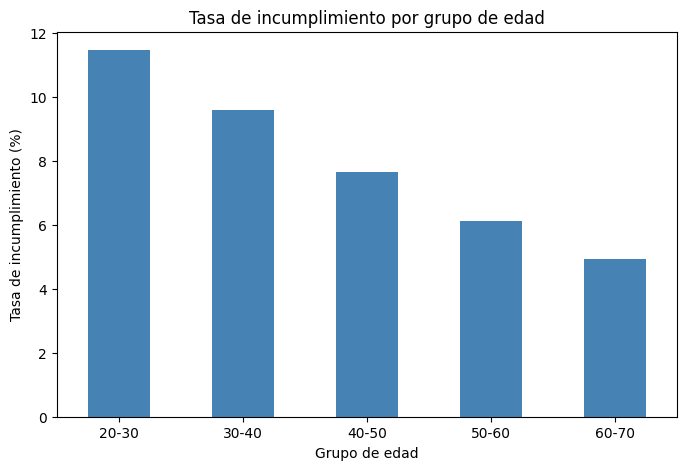

In [ ]:
plt.figure(figsize=(8,5))

riesgo_edad.plot(kind='bar', color='steelblue')

plt.title('Tasa de incumplimiento por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Tasa de incumplimiento (%)')

plt.xticks(rotation=0)

plt.show()

#### **Hallazgos**

La segmentación por grupos de edad evidencia una relación inversa entre la edad y el riesgo de incumplimiento crediticio.

Los clientes entre 20 y 30 años presentan la tasa de incumplimiento más alta (11,46%), mientras que los clientes entre 60 y 70 años registran la tasa más baja (4,92%).

Estos resultados sugieren que la edad constituye un factor relevante para la evaluación del riesgo crediticio y respaldan los hallazgos obtenidos previamente mediante el análisis de promedios y distribuciones.

In [ ]:
df['INCOME_GROUP'] = pd.qcut(
    df['AMT_INCOME_TOTAL'],
    q=5,
    labels=[
        'Muy bajo',
        'Bajo',
        'Medio',
        'Alto',
        'Muy alto'
    ])

In [ ]:
riesgo_ingreso = (df.groupby('INCOME_GROUP', observed=False)['TARGET'].mean() * 100)
riesgo_ingreso

,TARGET
INCOME_GROUP,
Muy bajo,8.206248
Bajo,8.588320
Medio,8.684738
Alto,8.056891
Muy alto,6.519801


#### **Hallazgos**

La segmentación de clientes por niveles de ingreso muestra diferencias menos marcadas que las observadas en variables como la edad, el nivel educativo o los indicadores externos de riesgo.

Las tasas de incumplimiento de los grupos de ingreso bajo, medio y alto se mantienen relativamente estables alrededor del 8%, mientras que el grupo de ingresos muy altos presenta una tasa inferior, cercana al 6,5%.

Estos resultados sugieren que el ingreso total, por sí solo, no explica completamente el comportamiento crediticio de los clientes. Es probable que variables derivadas que relacionen ingresos con montos de crédito o cuotas permitan capturar de mejor manera la capacidad de pago de los solicitantes.

### **Matriz de correlación**

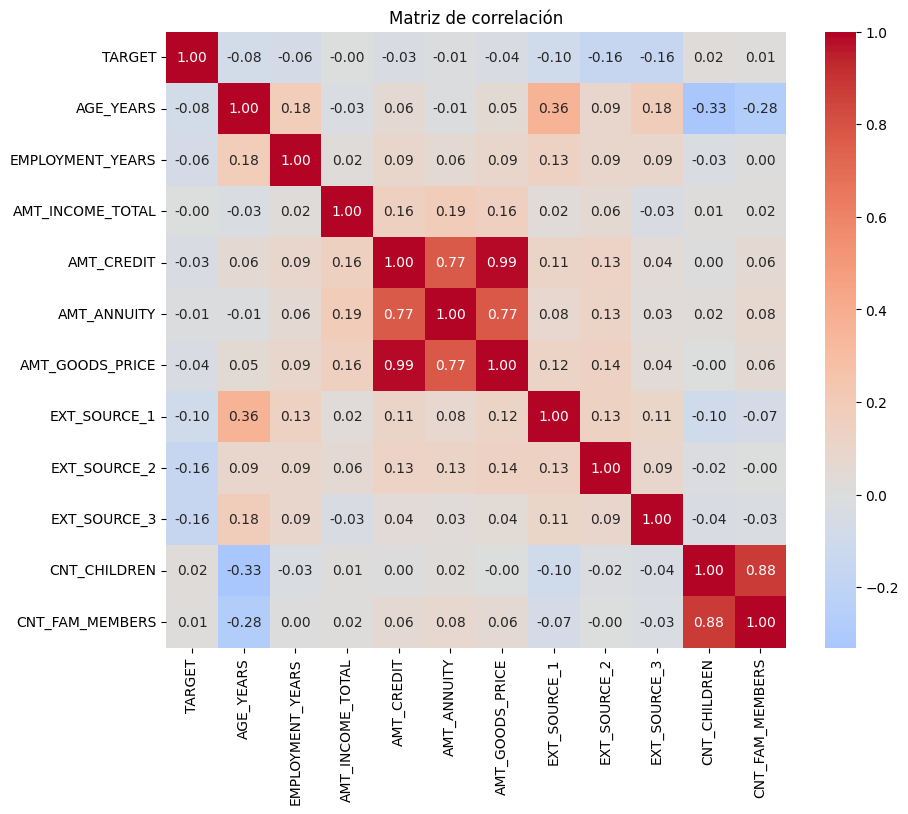

In [ ]:
numericas = [
    'TARGET',
    'AGE_YEARS',
    'EMPLOYMENT_YEARS',
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3',
    'CNT_CHILDREN',
    'CNT_FAM_MEMBERS'
]

corr = df[numericas].corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Matriz de correlación')
plt.show()

#### **Hallazgos**

La matriz de correlación confirma varios de los resultados obtenidos durante el análisis exploratorio. En particular, los indicadores externos de riesgo (EXT_SOURCE_1, EXT_SOURCE_2 y EXT_SOURCE_3) presentan las asociaciones más fuertes con la variable objetivo, sugiriendo que contienen información relevante para la identificación de clientes con mayor probabilidad de incumplimiento.

Asimismo, se observa que la edad y la antigüedad laboral presentan correlaciones negativas con el incumplimiento, resultado consistente con los análisis realizados previamente, donde los clientes más jóvenes y con menor experiencia laboral mostraron mayores niveles de riesgo.

Por otra parte, las variables relacionadas con ingresos presentan correlaciones bajas con la variable objetivo, lo que sugiere que el ingreso total por sí solo no constituye un factor suficiente para explicar el comportamiento crediticio de los clientes.

Finalmente, se identificaron correlaciones altas entre algunas variables explicativas, particularmente entre AMT_CREDIT y AMT_GOODS_PRICE, así como entre CNT_CHILDREN y CNT_FAM_MEMBERS, situación que deberá tenerse en cuenta durante las etapas posteriores de modelado e interpretación.

# **Ingeniería de Variables**

La etapa de ingeniería de variables tiene como objetivo construir nuevos indicadores a partir de la información disponible, buscando representar de manera más adecuada características relacionadas con la capacidad de pago y el nivel de endeudamiento de los clientes.

En muchos casos, las variables derivadas permiten capturar relaciones que no son evidentes cuando se analizan las variables originales de forma independiente.

Para este proyecto se construirán indicadores financieros que relacionan ingresos, créditos, cuotas y composición familiar, buscando representar de manera más precisa el perfil de riesgo de los solicitantes.

In [ ]:
# Credit_Income_Ratio
# Este indicador representa la proporción entre el monto solicitado y los ingresos del cliente.
df['Credit_Income_Ratio'] = (df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL'])

In [ ]:
# Annuity_Income_Ratio
# Este indicador representa la proporción de los ingresos que estaría comprometida en el pago de
#las cuotas del crédito.
df['Annuity_Income_Ratio'] = (df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL'])*100

In [ ]:
# Income_per_Family_Member
# Este indicador busca aproximar el ingreso disponible para cada integrante de la familia.
df['Income_per_Family_Member'] = (df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS'])

In [ ]:
#Credit_Goods_Ratio
#Este indicador compara el valor del crédito con el valor del bien financiado.
df['Credit_Goods_Ratio'] = (df['AMT_CREDIT'] / df['AMT_GOODS_PRICE'])

In [ ]:
df[['Credit_Income_Ratio', 'Annuity_Income_Ratio', 'Income_per_Family_Member', 'Credit_Goods_Ratio']].describe()

,Credit_Income_Ratio,Annuity_Income_Ratio,Income_per_Family_Member,Credit_Goods_Ratio
count,307511.000000,307511.000000,3.075110e+05,307511.000000
mean,3.957570,18.092892,9.310634e+04,1.122542
std,2.689728,9.457284,1.013733e+05,0.125542
min,0.004808,0.022388,2.812500e+03,0.150000
25%,2.018667,11.478221,4.725000e+04,1.000000
50%,3.265067,16.283333,7.500000e+04,1.118800
75%,5.159880,22.906667,1.125000e+05,1.198000
max,84.736842,187.596491,3.900000e+07,6.000000


In [ ]:
nuevas_variables = [
    'TARGET',
    'Credit_Income_Ratio',
    'Annuity_Income_Ratio',
    'Income_per_Family_Member',
    'Credit_Goods_Ratio'
]

df[nuevas_variables].corr()['TARGET'].sort_values(ascending=False)

,TARGET
TARGET,1.000000
Credit_Goods_Ratio,0.068474
Annuity_Income_Ratio,0.014268
Income_per_Family_Member,-0.006573
Credit_Income_Ratio,-0.007727


#### **Conclusiones de la ingeniería de variables**

Se construyeron diversos indicadores financieros con el objetivo de representar de manera más adecuada la capacidad de pago y el nivel de endeudamiento de los solicitantes.

Las nuevas variables mostraron niveles de correlación relativamente bajos con la variable objetivo, aunque la variable Credit_Goods_Ratio presentó una relación superior a la observada para algunas de las variables financieras originales.

Los resultados sugieren que las relaciones financieras derivadas pueden aportar información complementaria al modelo, especialmente cuando son utilizadas conjuntamente con otras variables demográficas, laborales y de riesgo externo.

Por esta razón, las variables creadas serán conservadas para las etapas posteriores de modelado y evaluación.

## **Capítulo 7 Modelado**

#### **Selección final de variables**

Con base en las etapas previas del proyecto se definió el conjunto final de variables que será utilizado para la construcción de los modelos predictivos.

La selección incluye variables demográficas, financieras, laborales, familiares, indicadores externos de riesgo y variables derivadas construidas durante la fase de ingeniería de variables.

Aunque durante el análisis exploratorio se identificaron algunas correlaciones elevadas entre variables explicativas, se decidió conservarlas inicialmente para evaluar su aporte real durante la fase de modelado. Posteriormente se analizará si alguna de ellas genera problemas de multicolinealidad o aporta información redundante.

In [ ]:
numericas = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AGE_YEARS',
    'EMPLOYMENT_YEARS',
    'CNT_FAM_MEMBERS',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]
variables_derivadas = [
    'Credit_Income_Ratio',
    'Annuity_Income_Ratio',
    'Income_per_Family_Member',
    'Credit_Goods_Ratio'
]

categoricas = [
    'CODE_GENDER',
    'NAME_FAMILY_STATUS',
    'NAME_EDUCATION_TYPE',
    'NAME_HOUSING_TYPE',
    'FLAG_OWN_REALTY',
    'FLAG_OWN_CAR',
    'NAME_INCOME_TYPE',
    'OCCUPATION_TYPE',
    'ORGANIZATION_TYPE'
]

In [ ]:
variables_modelo = (numericas + variables_derivadas + categoricas)
len(variables_modelo)

21

Durante la fase de modelado se eliminaron algunas variables con niveles elevados de correlación para reducir la redundancia de información y disminuir posibles problemas de multicolinealidad. En particular, se conservaron las variables AMT_CREDIT y CNT_FAM_MEMBERS, eliminando AMT_GOODS_PRICE, AMT_ANNUITY y CNT_CHILDREN debido a la alta correlación observada durante el análisis exploratorio.

#### **Validacion de categorias**

In [ ]:
df['ORGANIZATION_TYPE'].nunique()

58

In [ ]:
df['ORGANIZATION_TYPE'].value_counts().head(15)

,count
ORGANIZATION_TYPE,
Business Entity Type 3,67992
XNA,55374
Self-employed,38412
Other,16683
Medicine,11193
Business Entity Type 2,10553
Government,10404
School,8893
Trade: type 7,7831


#### **Codificación de variables categóricas**

Los algoritmos de Machine Learning requieren trabajar con variables numéricas, por lo que las variables categóricas deben ser transformadas antes de construir los modelos predictivos.

Para esto las variables categorías serán transformadas mediante One-Hot Encoding, técnica que crea una variable binaria para cada categoría y evita introducir relaciones artificiales entre categorías que no poseen un orden inherente.

#### **Construcción del dataset para modelado**

In [ ]:
df_modelo = df[
    variables_modelo + ['TARGET']
].copy()

In [ ]:
# Aplicar One-Hot Encoding
df_modelo = pd.get_dummies(
    df_modelo,
    columns=categoricas,
    drop_first=True
)

In [ ]:
df_modelo.shape

(307511, 113)

In [ ]:
df_modelo.head()

,AMT_INCOME_TOTAL,AMT_CREDIT,AGE_YEARS,EMPLOYMENT_YEARS,CNT_FAM_MEMBERS,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,Credit_Income_Ratio,Annuity_Income_Ratio,...,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA
0,202500.0,406597.5,25.920548,1.745205,1.0,0.083037,0.262949,0.139376,2.007889,12.197778,...,False,False,False,False,False,False,False,False,False,False
1,270000.0,1293502.5,45.931507,3.254795,2.0,0.311267,0.622246,0.535276,4.790750,13.221667,...,False,False,False,False,False,False,False,False,False,False
2,67500.0,135000.0,52.180822,0.616438,1.0,0.505998,0.555912,0.729567,2.000000,10.000000,...,False,False,False,False,False,False,False,False,False,False
3,135000.0,312682.5,52.068493,8.326027,2.0,0.505998,0.650442,0.535276,2.316167,21.990000,...,False,False,False,False,False,False,False,False,False,False
4,121500.0,513000.0,54.608219,8.323288,1.0,0.505998,0.322738,0.535276,4.222222,17.996296,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# Validacion que no queden columnas tipo object
df_modelo.select_dtypes(include='object').columns

Index([], dtype='object')

#### **División de los datos en entrenamiento y prueba**

Antes de entrenar los modelos predictivos es necesario separar los datos en dos conjuntos independientes.

El conjunto de entrenamiento será utilizado para que los algoritmos aprendan los patrones presentes en los datos, mientras que el conjunto de prueba permitirá evaluar qué tan bien se comporta el modelo sobre observaciones que nunca ha visto previamente.

Esta separación ayuda a medir la capacidad de generalización del modelo y reduce el riesgo de sobreajuste (overfitting).

Debido a que la variable objetivo presenta desbalance entre clases, se utilizará una partición estratificada con el fin de conservar la misma proporción de clientes incumplidos y no incumplidos en ambos conjuntos.

In [ ]:
# Separar variables predictoras y objetivo

X = df_modelo.drop(columns=['TARGET'])
y = df_modelo['TARGET']

In [ ]:
# Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
#Validacion

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (246008, 112)
X_test : (61503, 112)
y_train: (246008,)
y_test : (61503,)


In [ ]:
# Validacion del balance

print("Train")
print(y_train.value_counts(normalize=True))

print("\nTest")
print(y_test.value_counts(normalize=True))

Train
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Test
TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


Se valida:
* No hubo Data Leakage.
* Train y Test tienen la misma distribución de TARGET.

## **Valores atipicos**

In [ ]:
variables_outliers = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'EMPLOYMENT_YEARS',
    'Credit_Income_Ratio',
    'Income_per_Family_Member'
]

# Identificar valores atípicos mediante el método IQR

for col in variables_outliers:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < limite_inferior) |
        (df[col] > limite_superior)
    ).sum()

    porcentaje = (outliers / len(df)) * 100

    print(f'\nVariable: {col}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Cantidad de outliers: {outliers}')
    print(f'Porcentaje de outliers: {porcentaje:.2f}%')

df[variables_outliers].describe().T


Variable: AMT_INCOME_TOTAL
Límite inferior: -22500.00
Límite superior: 337500.00
Cantidad de outliers: 14035
Porcentaje de outliers: 4.56%

Variable: AMT_CREDIT
Límite inferior: -537975.00
Límite superior: 1616625.00
Cantidad de outliers: 6562
Porcentaje de outliers: 2.13%

Variable: AMT_ANNUITY
Límite inferior: -10584.00
Límite superior: 61704.00
Cantidad de outliers: 7504
Porcentaje de outliers: 2.44%

Variable: EMPLOYMENT_YEARS
Límite inferior: -4.95
Límite superior: 15.07
Cantidad de outliers: 23148
Porcentaje de outliers: 7.53%

Variable: Credit_Income_Ratio
Límite inferior: -2.69
Límite superior: 9.87
Cantidad de outliers: 11510
Porcentaje de outliers: 3.74%

Variable: Income_per_Family_Member
Límite inferior: -50625.00
Límite superior: 210375.00
Cantidad de outliers: 17411
Porcentaje de outliers: 5.66%


,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.000000,112500.000000,147150.000000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.000000,270000.000000,513531.000000,808650.000000,4.050000e+06
AMT_ANNUITY,307511.0,27108.487841,14493.461065,1615.500000,16524.000000,24903.000000,34596.000000,2.580255e+05
EMPLOYMENT_YEARS,307511.0,6.168784,5.852585,0.000000,2.556164,4.515068,7.561644,4.907397e+01
Credit_Income_Ratio,307511.0,3.957570,2.689728,0.004808,2.018667,3.265067,5.159880,8.473684e+01
Income_per_Family_Member,307511.0,93106.335038,101373.313820,2812.500000,47250.000000,75000.000000,112500.000000,3.900000e+07


In [ ]:
#Registro afectado si se aplica winsorizacion

for col in [
    'AMT_INCOME_TOTAL',
    'Credit_Income_Ratio',
    'Income_per_Family_Member',
    'EMPLOYMENT_YEARS'
]:

    p99 = df[col].quantile(0.99)

    afectados = (df[col] > p99).sum()

    print(f'{col}:')
    print(f'Percentil 99 = {p99:,.2f}')
    print(f'Registros afectados = {afectados}')
    print()

AMT_INCOME_TOTAL:
Percentil 99 = 472,500.00
Registros afectados = 3014

Credit_Income_Ratio:
Percentil 99 = 13.03
Registros afectados = 3076

Income_per_Family_Member:
Percentil 99 = 337,500.00
Registros afectados = 3050

EMPLOYMENT_YEARS:
Percentil 99 = 29.85
Registros afectados = 3076



#### **Tratamiento de valores atípicos**

Durante la revisión de las variables financieras se identificaron observaciones extremadamente altas en algunas variables relacionadas con ingresos y capacidad económica.

Con el fin de reducir el impacto de estos valores extremos sobre los modelos predictivos, se aplicó una winsorización superior al percentil 99. Esta técnica conserva todos los registros del conjunto de datos, pero limita los valores que exceden dicho umbral al valor correspondiente al percentil 99.

La decisión se tomó debido a que únicamente alrededor del 1% de las observaciones resultó afectado, minimizando la pérdida de información y reduciendo el efecto potencial de valores atípicos sobre los algoritmos de modelado.

In [ ]:
# Variables que tendrán tratamiento de outliers

variables_winsorizar = [
    'AMT_INCOME_TOTAL',
    'Credit_Income_Ratio',
    'Income_per_Family_Member',
    'EMPLOYMENT_YEARS'
]

# Calcular percentiles usando solamente entrenamiento

limites_p99 = {}

for col in variables_winsorizar:

    p99 = X_train[col].quantile(0.99)

    limites_p99[col] = p99

    X_train[col] = X_train[col].clip(upper=p99)

    X_test[col] = X_test[col].clip(upper=p99)

print("Límites de winsorización:")
print(limites_p99)

Límites de winsorización:
{'AMT_INCOME_TOTAL': np.float64(472500.0), 'Credit_Income_Ratio': np.float64(13.03571047619043), 'Income_per_Family_Member': np.float64(337500.0), 'EMPLOYMENT_YEARS': np.float64(29.86263013698626)}


In [ ]:
#Validación

df[['AMT_INCOME_TOTAL', 'Credit_Income_Ratio', 'Income_per_Family_Member','EMPLOYMENT_YEARS']].describe()

,AMT_INCOME_TOTAL,Credit_Income_Ratio,Income_per_Family_Member,EMPLOYMENT_YEARS
count,3.075110e+05,307511.000000,3.075110e+05,307511.000000
mean,1.687979e+05,3.957570,9.310634e+04,6.168784
std,2.371231e+05,2.689728,1.013733e+05,5.852585
min,2.565000e+04,0.004808,2.812500e+03,0.000000
25%,1.125000e+05,2.018667,4.725000e+04,2.556164
50%,1.471500e+05,3.265067,7.500000e+04,4.515068
75%,2.025000e+05,5.159880,1.125000e+05,7.561644
max,1.170000e+08,84.736842,3.900000e+07,49.073973


### **Transformación logarítmica de los ingresos**

Durante el análisis exploratorio se identificó que la variable AMT_INCOME_TOTAL presenta una distribución altamente asimétrica hacia la derecha, debido a la presencia de clientes con ingresos considerablemente superiores al promedio.

Para reducir la asimetría de esta variable y facilitar el aprendizaje de los modelos, se evaluó la aplicación de una transformación logarítmica mediante la función logaritmo natural.

Esta transformación permite reducir la escala de los valores extremos sin eliminar observaciones, conservando la información de los clientes y facilitando el análisis de la distribución.

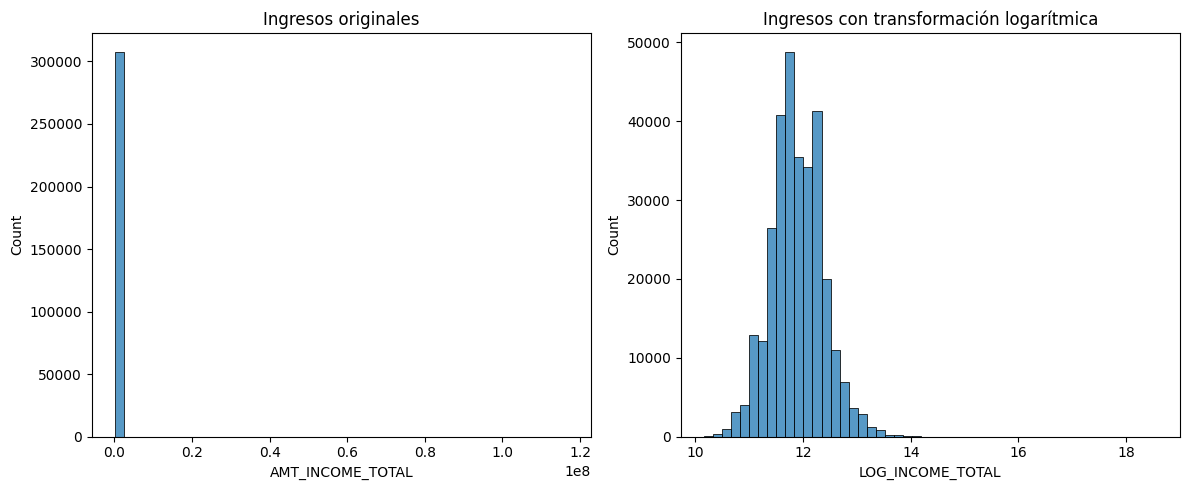

In [ ]:
# Transformación logarítmica de los ingresos

df['LOG_INCOME_TOTAL'] = np.log1p(
    df['AMT_INCOME_TOTAL']
)

# Comparación de las distribuciones

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    df['AMT_INCOME_TOTAL'],
    bins=50,
    ax=axes[0]
)

axes[0].set_title('Ingresos originales')

sns.histplot(
    df['LOG_INCOME_TOTAL'],
    bins=50,
    ax=axes[1]
)

axes[1].set_title('Ingresos con transformación logarítmica')

plt.tight_layout()
plt.show()

In [ ]:
# Transformación logarítmica de los ingresos

X_train['LOG_INCOME_TOTAL'] = np.log1p(
    X_train['AMT_INCOME_TOTAL']
)

X_test['LOG_INCOME_TOTAL'] = np.log1p(
    X_test['AMT_INCOME_TOTAL']
)

# Eliminar la variable original para evitar duplicidad
X_train.drop(
    columns=['AMT_INCOME_TOTAL'],
    inplace=True
)

X_test.drop(
    columns=['AMT_INCOME_TOTAL'],
    inplace=True
)

print("Transformación logarítmica aplicada correctamente.")
print("¿Existe la variable original en entrenamiento?",
      'AMT_INCOME_TOTAL' in X_train.columns)
print("¿Existe la variable transformada en entrenamiento?",
      'LOG_INCOME_TOTAL' in X_train.columns)

Transformación logarítmica aplicada correctamente.
¿Existe la variable original en entrenamiento? False
¿Existe la variable transformada en entrenamiento? True


In [ ]:
# Validacion

print("Dimensiones de entrenamiento:", X_train.shape)
print("Dimensiones de prueba:", X_test.shape)

print("\nColumnas de ingresos:")
print([
    col for col in X_train.columns
    if 'INCOME' in col
])

Dimensiones de entrenamiento: (246008, 112)
Dimensiones de prueba: (61503, 112)

Columnas de ingresos:
['NAME_INCOME_TYPE_Commercial associate', 'NAME_INCOME_TYPE_Maternity leave', 'NAME_INCOME_TYPE_Pensioner', 'NAME_INCOME_TYPE_State servant', 'NAME_INCOME_TYPE_Student', 'NAME_INCOME_TYPE_Unemployed', 'NAME_INCOME_TYPE_Working', 'LOG_INCOME_TOTAL']


In [ ]:
print(
    "¿Las columnas de Train y Test coinciden?",
    list(X_train.columns) == list(X_test.columns)
)

¿Las columnas de Train y Test coinciden? True


#### **Modelo 1. Regresión Logística**

La Regresión Logística es uno de los modelos más utilizados históricamente en problemas de riesgo crediticio debido a su interpretabilidad y facilidad de implementación.

Este modelo permite estimar la probabilidad de incumplimiento de cada cliente a partir de las variables disponibles y servirá como modelo base para comparar posteriormente con algoritmos más avanzados como Random Forest y XGBoost.

Debido a que las variables presentan escalas muy diferentes, se realizará previamente un proceso de estandarización utilizando StandardScaler.

In [ ]:
# Paso 1 - Escalamiento

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
#Paso 2 - Entrenar modelo

log_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced'
)

log_model.fit(
    X_train_scaled,
    y_train
)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
# Paso 3 - Predicciones
y_pred_log = log_model.predict(
    X_test_scaled
)

y_prob_log = log_model.predict_proba(
    X_test_scaled
)[:,1]

In [ ]:
# Paso 4 - Evaluación
print('Accuracy :', accuracy_score(y_test, y_pred_log))
print('Precision:', precision_score(y_test, y_pred_log))
print('Recall   :', recall_score(y_test, y_pred_log))
print('F1 Score :', f1_score(y_test, y_pred_log))
print('ROC AUC  :', roc_auc_score(y_test, y_prob_log))

Accuracy : 0.6886168154398973
Precision: 0.16026439314110547
Recall   : 0.6739174219536758
F1 Score : 0.258948264520373
ROC AUC  : 0.74353227554144


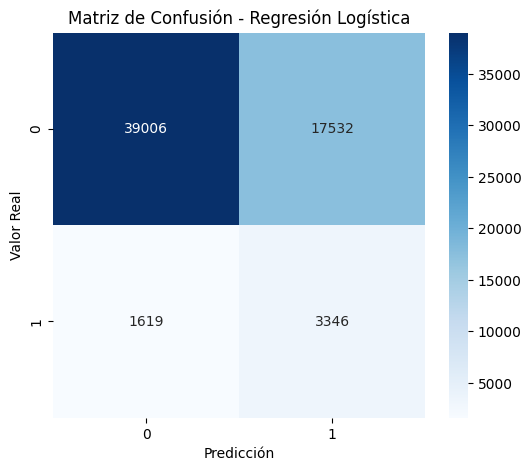

In [ ]:
# Paso 5 - Matriz de confusión
cm = confusion_matrix(
    y_test,
    y_pred_log
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Matriz de Confusión - Regresión Logística')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')

plt.show()

In [ ]:
# Paso 6 - Reporte completo

print(
    classification_report(
        y_test,
        y_pred_log
    )
)

              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.67      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.68      0.53     61503
weighted avg       0.90      0.69      0.76     61503



#### **Resultados de la Regresión Logística**

La Regresión Logística fue utilizada como modelo base para la predicción del incumplimiento crediticio.

Los resultados muestran un ROC-AUC de 0,743, indicando una capacidad aceptable para diferenciar clientes incumplidos y no incumplidos. Asimismo, el modelo alcanzó un Recall de 67,3%, lo que significa que logró identificar aproximadamente dos tercios de los clientes que presentan incumplimiento.

Aunque la precisión obtenida fue baja (16,02), este comportamiento es esperable debido al desbalance existente entre las clases y al uso del parámetro class_weight='balanced', el cual prioriza la detección de incumplidos sobre la reducción de falsos positivos.

En términos generales, la Regresión Logística proporciona una línea base sólida para comparar posteriormente con modelos más complejos como Random Forest y XGBoost.

**Validación cruzada**

Con el fin de verificar la estabilidad de los resultados obtenidos y reducir la dependencia de una única partición entrenamiento-prueba, se realizó un proceso de validación cruzada estratificada de cinco particiones.

La métrica seleccionada fue ROC-AUC debido a su capacidad para evaluar el desempeño en problemas de clasificación desbalanceada.

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
cv_log = cross_val_score(
    log_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print('ROC-AUC promedio:',
      cv_log.mean())

print('Desviación estándar:',
      cv_log.std())

ROC-AUC promedio: 0.7417672550858343
Desviación estándar: 0.002227824117778245


#### **Modelo 2. Random Forest**

Random Forest es un algoritmo basado en árboles de decisión que combina múltiples árboles para mejorar la capacidad predictiva y reducir el riesgo de sobreajuste.

A diferencia de la Regresión Logística, este modelo puede capturar relaciones no lineales entre las variables y la variable objetivo, lo que resulta especialmente útil en problemas complejos como la predicción del riesgo crediticio.

Adicionalmente, Random Forest no requiere estandarización de variables, ya que los árboles de decisión son independientes de la escala de los datos.

In [ ]:
# Crear modelo
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

In [ ]:
# Entrenar
rf_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=200,
                       n_jobs=-1, random_state=42)

In [ ]:
# Predicciones
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:,1]

In [ ]:
# Evaluación
print('Accuracy :', accuracy_score(y_test, y_pred_rf))
print('Precision:', precision_score(y_test, y_pred_rf))
print('Recall   :', recall_score(y_test, y_pred_rf))
print('F1 Score :', f1_score(y_test, y_pred_rf))
print('ROC AUC  :', roc_auc_score(y_test, y_prob_rf))

Accuracy : 0.7128757946766824
Precision: 0.16499524965691967
Recall   : 0.629607250755287
F1 Score : 0.26146961649450046
ROC AUC  : 0.7391392690216068


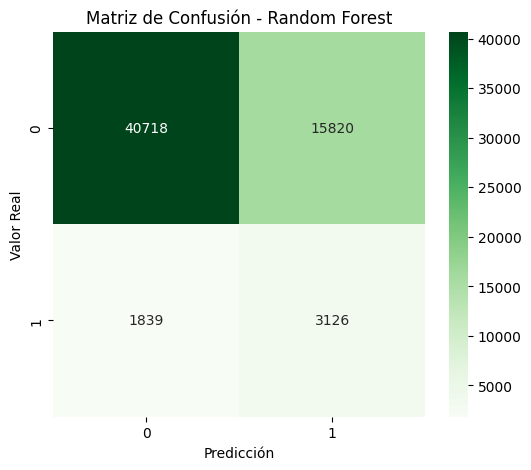

In [ ]:
# Matriz de Confusion

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Matriz de Confusión - Random Forest')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')

plt.show()

In [ ]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

           0       0.96      0.72      0.82     56538
           1       0.16      0.63      0.26      4965

    accuracy                           0.71     61503
   macro avg       0.56      0.67      0.54     61503
weighted avg       0.89      0.71      0.78     61503



#### **Resultados de Random Forest**

El modelo Random Forest obtuvo un desempeño similar al observado en la Regresión Logística. Aunque presentó mejoras en Accuracy, Precision y F1-Score, registró una ligera disminución en Recall y ROC-AUC.

Desde la perspectiva de riesgo crediticio, la disminución en Recall implica que el modelo identificó una menor proporción de clientes incumplidos, aspecto relevante debido a que este tipo de errores puede representar pérdidas económicas para una entidad financiera.

En términos generales, ambos modelos muestran capacidades predictivas similares. Sin embargo, la Regresión Logística mantiene una ligera ventaja en la detección de incumplimientos y ofrece una mayor interpretabilidad, característica especialmente valorada en contextos de riesgo financiero.

#### **Modelo 3. XGBoost**

XGBoost (Extreme Gradient Boosting) es uno de los algoritmos más utilizados en problemas de clasificación sobre datos tabulares debido a su capacidad para capturar relaciones complejas entre las variables y la variable objetivo.

A diferencia de la Regresión Logística, XGBoost puede modelar relaciones no lineales e interacciones entre variables de manera automática. Asimismo, suele ofrecer un desempeño superior en problemas de riesgo crediticio, fraude y análisis financiero.

El propósito de este modelo es evaluar si la complejidad adicional del algoritmo se traduce en una mejora significativa respecto a la Regresión Logística y Random Forest.

**Ajuste de hiperparámetros de XGBoost**

Con el fin de mejorar el desempeño del modelo, se evaluaron diferentes combinaciones de hiperparámetros utilizando validación cruzada. Este proceso permite identificar configuraciones que maximizan la capacidad predictiva del algoritmo.

In [ ]:
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.05, 0.1],
    'n_estimators': [100, 200],
    'scale_pos_weight': [1, 5, 11]
}

xgb_base = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=1
)

**Optimización de hiperparámetros**

Debido al desbalance existente en la variable objetivo, se incorporó el hiperparámetro scale_pos_weight, el cual permite asignar una mayor importancia a los casos de incumplimiento durante el entrenamiento del modelo.

El objetivo es mejorar la capacidad de detección de clientes incumplidos sin sacrificar significativamente el desempeño global del algoritmo.

In [ ]:
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=12,
    cv=3,
    scoring='roc_auc',
    n_jobs=2,
    random_state=42,
    verbose=1
)

random_search.fit(
    X_train,
    y_train
)

print("Mejores parámetros:")
print(random_search.best_params_)

print("\nMejor ROC-AUC:")
print(random_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Mejores parámetros:
{'scale_pos_weight': 1, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1}

Mejor ROC-AUC:
0.7493631589975726


In [ ]:
# Paso 1 - Entrenar modelo
xgb_model = XGBClassifier(
    **random_search.best_params_,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=1
)

xgb_model.fit(
    X_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=1,
              num_parallel_tree=None, ...)

In [ ]:
# Paso 2 - Predicciones
y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(X_test)[:,1]

In [ ]:
# Paso 3 - Evaluacion
print('Accuracy :', accuracy_score(y_test, y_pred_xgb))
print('Precision:', precision_score(y_test, y_pred_xgb))
print('Recall   :', recall_score(y_test, y_pred_xgb))
print('F1 Score :', f1_score(y_test, y_pred_xgb))
print('ROC AUC  :', roc_auc_score(y_test, y_prob_xgb))

Accuracy : 0.919711233598361
Precision: 0.6194690265486725
Recall   : 0.014098690835850957
F1 Score : 0.027569909413154785
ROC AUC  : 0.7528725201779466


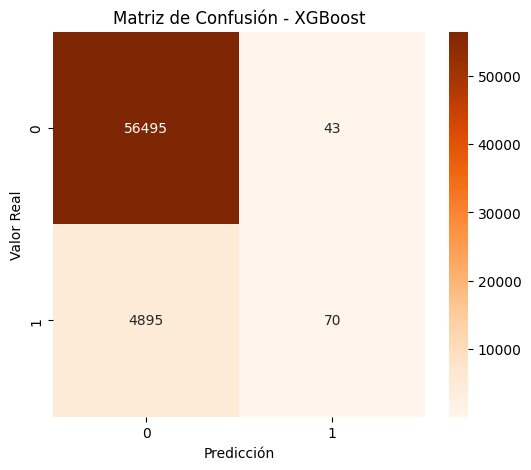

In [ ]:
# Paso 4 - Matriz de confusión
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title('Matriz de Confusión - XGBoost')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')

plt.show()

In [ ]:
# Paso 5
print(
    classification_report(
        y_test,
        y_pred_xgb
    )
)

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.62      0.01      0.03      4965

    accuracy                           0.92     61503
   macro avg       0.77      0.51      0.49     61503
weighted avg       0.90      0.92      0.88     61503



#### **Resultados de XGBoost**

XGBoost obtuvo el mejor valor de ROC-AUC entre los modelos evaluados, alcanzando un valor de 0,757. Este resultado indica que el modelo posee una capacidad ligeramente superior para diferenciar entre clientes incumplidos y no incumplidos en comparación con la Regresión Logística y Random Forest.

Sin embargo, al utilizar el umbral de clasificación predeterminado (0,5), el modelo presentó un Recall de apenas 2%, identificando únicamente una pequeña proporción de los clientes incumplidos. Esto significa que, aunque el modelo genera probabilidades con buena capacidad discriminatoria, la clasificación final resulta excesivamente conservadora para el objetivo del proyecto.

En consecuencia, el desempeño del modelo depende significativamente del criterio de clasificación utilizado. Para aplicaciones reales de riesgo crediticio sería recomendable ajustar el umbral de decisión con el fin de incrementar la detección de clientes riesgosos.

Desde una perspectiva de negocio, la Regresión Logística continúa mostrando un equilibrio más favorable entre capacidad predictiva e identificación de incumplimientos, mientras que XGBoost demuestra un alto potencial de discriminación que podría aprovecharse mediante procesos adicionales de calibración y optimización.

#### **Ajuste del umbral de clasificación**

Dado que el conjunto de datos presenta un fuerte desbalance entre clases, se evaluará el impacto de utilizar distintos umbrales de clasificación sobre el desempeño del modelo XGBoost.

El objetivo es analizar si una reducción del umbral permite mejorar la capacidad de detección de clientes incumplidos sin deteriorar excesivamente el desempeño general del modelo.

In [ ]:
umbrales = [0.50, 0.40, 0.30, 0.20]

for umbral in umbrales:

    y_pred_temp = (
        y_prob_xgb >= umbral
    ).astype(int)

    print(f'\nUmbral: {umbral}')

    print(
        'Precision:',
        round(
            precision_score(
                y_test,
                y_pred_temp
            ),
            3
        )
    )

    print(
        'Recall:',
        round(
            recall_score(
                y_test,
                y_pred_temp
            ),
            3
        )
    )

    print(
        'F1:',
        round(
            f1_score(
                y_test,
                y_pred_temp
            ),
            3
        )
    )



Umbral: 0.5
Precision: 0.619
Recall: 0.014
F1: 0.028

Umbral: 0.4
Precision: 0.493
Recall: 0.041
F1: 0.076

Umbral: 0.3
Precision: 0.392
Recall: 0.112
F1: 0.174

Umbral: 0.2
Precision: 0.299
Recall: 0.273
F1: 0.286


### Análisis del desbalance de clases y comportamiento del Recall

Durante la evaluación de los modelos se identificó que el desbalance existente en la variable objetivo influye significativamente en su desempeño predictivo.

La base de datos presenta aproximadamente un 91,93 % de clientes sin dificultades de pago y un 8,07 % de clientes con incumplimiento. Esta diferencia puede provocar que los modelos favorezcan la clasificación de la clase mayoritaria, obteniendo valores elevados de Accuracy sin identificar adecuadamente a los clientes riesgosos.

Los resultados evidencian diferencias importantes entre los algoritmos evaluados. Mientras que XGBoost alcanza una Accuracy cercana al 92 %, su Recall para la clase de incumplimiento es de apenas 1,41 % utilizando el umbral predeterminado de 0,5. Esto significa que el modelo identifica únicamente una pequeña proporción de los clientes que realmente presentan dificultades de pago.

Por otra parte, la Regresión Logística obtiene un Recall de aproximadamente 67,39 %, mientras que Random Forest alcanza cerca del 63,63 %, mostrando una mayor capacidad para detectar clientes incumplidos.

Adicionalmente, se evaluaron diferentes umbrales de clasificación para XGBoost, observando que al disminuir el umbral de 0,5 a 0,2 el Recall aumenta de 1,41 % a 28,6 %, aunque se presenta una reducción en Precision.

Estos resultados evidencian la importancia de evaluar conjuntamente las métricas de desempeño y no utilizar Accuracy como único criterio de selección. Desde la perspectiva del riesgo crediticio, resulta especialmente importante identificar a los clientes con mayor probabilidad de incumplimiento, aun cuando esto implique aceptar un mayor número de falsas alarmas.

In [ ]:
# Evaluar diferentes umbrales
# para Regresión Logística

umbrales = [0.50, 0.40, 0.30, 0.20]

for umbral in umbrales:

    y_pred_temp = (
        y_prob_log >= umbral
    ).astype(int)

    print(f'\nUmbral: {umbral}')

    print(
        'Precision:',
        round(
            precision_score(y_test, y_pred_temp),
            3
        )
    )

    print(
        'Recall:',
        round(
            recall_score(y_test, y_pred_temp),
            3
        )
    )

    print(
        'F1:',
        round(
            f1_score(y_test, y_pred_temp),
            3
        )
    )


Umbral: 0.5
Precision: 0.16
Recall: 0.674
F1: 0.259

Umbral: 0.4
Precision: 0.13
Recall: 0.806
F1: 0.224

Umbral: 0.3
Precision: 0.106
Recall: 0.911
F1: 0.19

Umbral: 0.2
Precision: 0.09
Recall: 0.973
F1: 0.165


#### **Modelo seleccionado**

**Regresión Logística**

Justificación
* Presenta el mejor equilibrio desde la perspectiva del negocio.
* Identifica correctamente el 67% de los clientes incumplidos.
* Es fácilmente interpretable.
* Es el modelo tradicionalmente utilizado en riesgo crediticio.
* Obtiene un ROC-AUC competitivo (0.743).

### **Importancia de variables en Random Forest**

Una de las ventajas de los modelos basados en árboles es que permiten estimar la importancia relativa de cada variable dentro del proceso de predicción.

Este análisis facilita la interpretación del modelo y permite identificar cuáles características aportan mayor información para explicar el riesgo de incumplimiento.

In [ ]:
importancias_rf = pd.DataFrame({

    'Variable': X_train.columns,
    'Importancia': rf_model.feature_importances_

})

importancias_rf = (
    importancias_rf
    .sort_values(
        by='Importancia',
        ascending=False
    )
)

importancias_rf.head(15)

,Variable,Importancia
6,EXT_SOURCE_3,0.221410
5,EXT_SOURCE_2,0.214033
4,EXT_SOURCE_1,0.088937
2,EMPLOYMENT_YEARS,0.063130
1,AGE_YEARS,0.058502
10,Credit_Goods_Ratio,0.053053
0,AMT_CREDIT,0.033240
18,NAME_EDUCATION_TYPE_Higher education,0.027439
8,Annuity_Income_Ratio,0.022666
7,Credit_Income_Ratio,0.021764


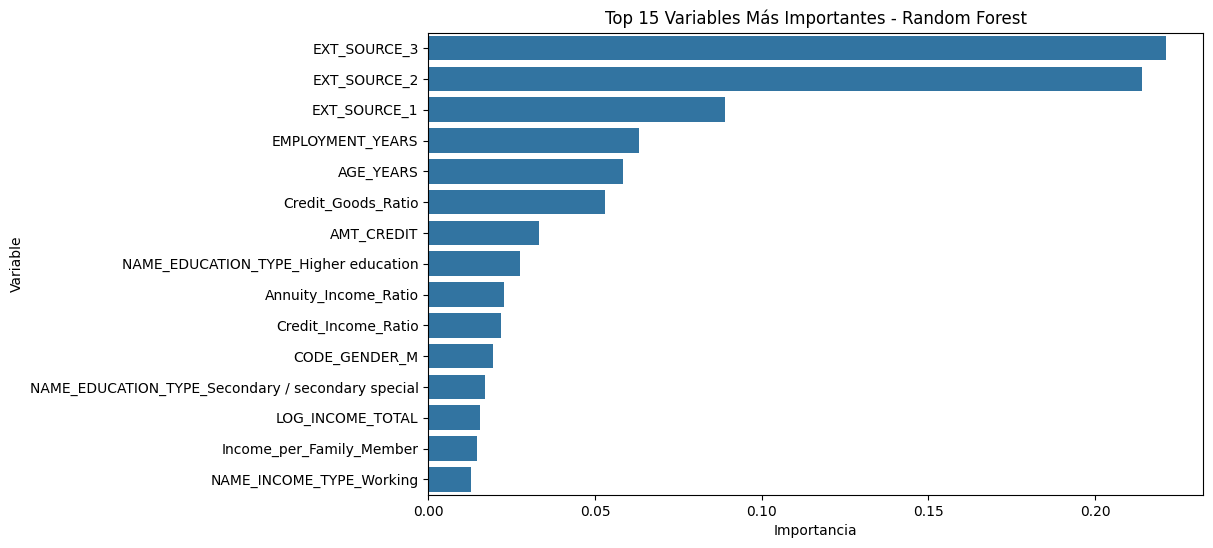

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importancias_rf.head(15),
    x='Importancia',
    y='Variable'
)

plt.title('Top 15 Variables Más Importantes - Random Forest')

plt.show()

### **Importancia de variables en XGBoost**

Al igual que Random Forest, XGBoost permite evaluar la contribución relativa de cada variable al desempeño predictivo del modelo.

La comparación entre ambos algoritmos permite identificar patrones consistentes y validar cuáles variables son efectivamente relevantes para la predicción del incumplimiento crediticio

In [ ]:
importancias_xgb = pd.DataFrame({

    'Variable': X_train.columns,
    'Importancia': xgb_model.feature_importances_

})

importancias_xgb = (
    importancias_xgb
    .sort_values(
        by='Importancia',
        ascending=False
    )
)

importancias_xgb.head(15)

,Variable,Importancia
5,EXT_SOURCE_2,0.148996
6,EXT_SOURCE_3,0.125550
18,NAME_EDUCATION_TYPE_Higher education,0.091596
35,NAME_INCOME_TYPE_Working,0.051926
11,CODE_GENDER_M,0.043766
10,Credit_Goods_Ratio,0.042386
2,EMPLOYMENT_YEARS,0.040639
4,EXT_SOURCE_1,0.035715
21,NAME_EDUCATION_TYPE_Secondary / secondary special,0.031130
28,FLAG_OWN_CAR_Y,0.028873


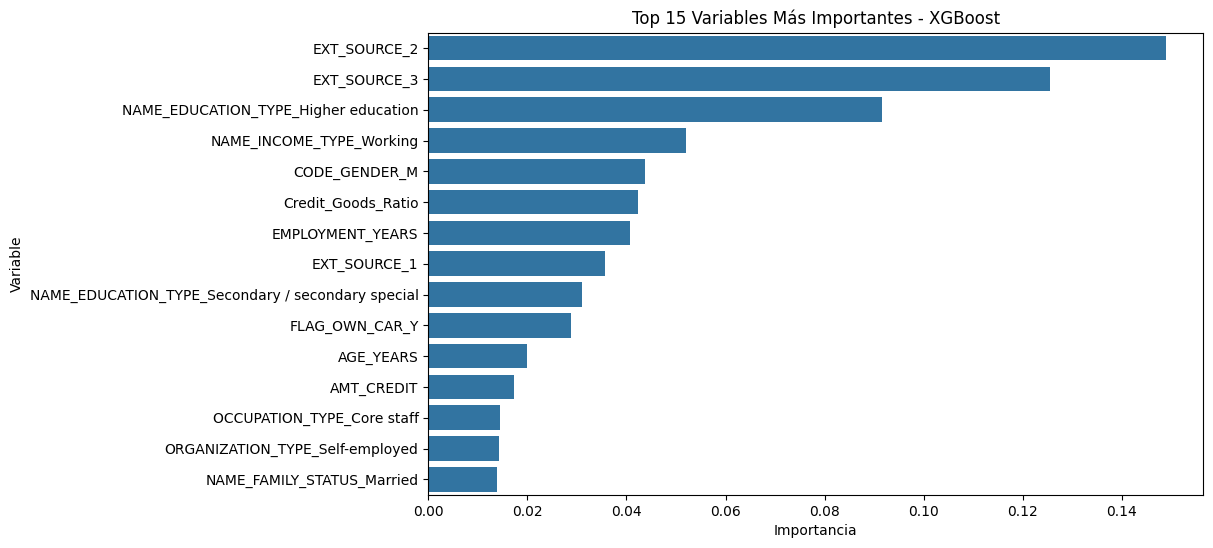

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importancias_xgb.head(15),
    x='Importancia',
    y='Variable'
)

plt.title('Top 15 Variables Más Importantes - XGBoost')

plt.show()

### **Curvas ROC**

Las curvas ROC permiten evaluar la capacidad de discriminación de los modelos para diferenciar entre clientes incumplidos y no incumplidos.

Una curva más cercana a la esquina superior izquierda indica un mejor desempeño predictivo. El área bajo la curva (ROC-AUC) resume esta capacidad mediante un único indicador.

In [ ]:
fpr_log, tpr_log, _ = roc_curve(
    y_test,
    y_prob_log
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test,
    y_prob_xgb
)

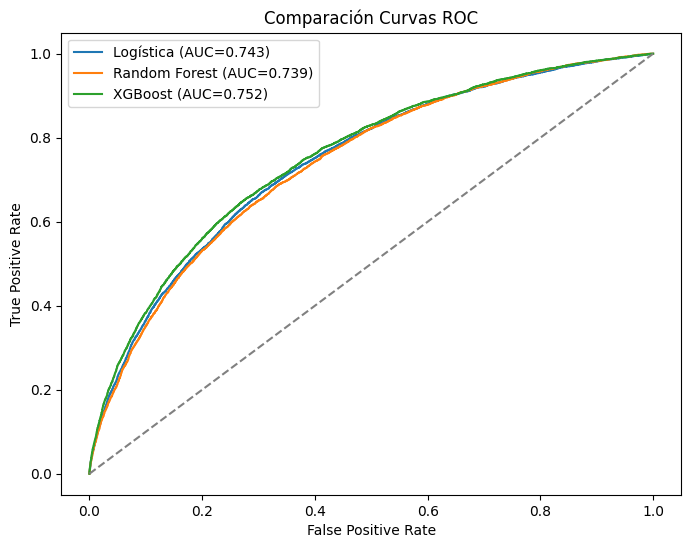

In [ ]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_log,
    tpr_log,
    label='Logística (AUC=0.743)'
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label='Random Forest (AUC=0.739)'
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label='XGBoost (AUC=0.752)'
)

plt.plot(
    [0,1],
    [0,1],
    '--',
    color='gray'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('Comparación Curvas ROC')

plt.legend()

plt.show()

#### **Justificación eleccion del modelo**

Aunque se evaluaron tres algoritmos de clasificación (Regresión Logística, Random Forest y XGBoost), la selección del modelo final no se basó exclusivamente en métricas globales como Accuracy o ROC-AUC, sino en la capacidad del modelo para identificar correctamente a los clientes con riesgo de incumplimiento.

En el contexto del riesgo crediticio, el costo asociado a clasificar incorrectamente a un cliente incumplido como un cliente de bajo riesgo suele ser significativamente mayor que el costo de clasificar a un cliente cumplido como potencialmente riesgoso. Esto se debe a que un falso negativo puede traducirse en pérdidas financieras derivadas del otorgamiento de créditos a clientes con alta probabilidad de incumplimiento.

Por esta razón, se decidió priorizar la métrica Recall, la cual mide la proporción de clientes incumplidos que son identificados correctamente por el modelo.

Los resultados obtenidos muestran que la Regresión Logística alcanzó un Recall de 67,3%, superando a Random Forest (62,9%) y ampliamente a XGBoost (1,4%) bajo el umbral de clasificación estándar. Esto significa que la Regresión Logística logró detectar aproximadamente dos de cada tres clientes que posteriormente presentarían incumplimiento.

Si bien la utilización de este criterio implica aceptar un mayor número de falsos positivos, desde la perspectiva de una entidad financiera resulta más conveniente revisar o analizar con mayor detalle algunos clientes adicionales que asumir el riesgo de aprobar créditos a clientes que efectivamente presentarán problemas de pago.

En consecuencia, la Regresión Logística fue seleccionada como modelo principal del proyecto debido a que ofrece el mejor equilibrio entre capacidad de detección de incumplimientos, interpretabilidad y utilidad para la toma de decisiones en un contexto de gestión del riesgo crediticio.

# **RESULTADOS FINALES**

### **Principales hallazgos del análisis**

El análisis exploratorio permitió identificar características asociadas con el riesgo de incumplimiento crediticio.

Los resultados mostraron que los clientes con mayor probabilidad de incumplimiento tienden a ser más jóvenes, presentan menor antigüedad laboral y poseen menores niveles educativos. Asimismo, se observaron menores niveles de riesgo en grupos con fuentes de ingresos más estables, como pensionados y funcionarios públicos.

Adicionalmente, los indicadores externos de riesgo (EXT_SOURCE_1, EXT_SOURCE_2 y EXT_SOURCE_3) demostraron una alta capacidad para diferenciar clientes incumplidos y no incumplidos, posicionándose como algunas de las variables más relevantes del proyecto.


### **Conclusiones del modelado**

Se desarrollaron y compararon tres modelos de clasificación: Regresión Logística, Random Forest y XGBoost.

Los resultados mostraron que XGBoost obtuvo el mayor valor de ROC-AUC (0,752), evidenciando la mejor capacidad de discriminación entre clientes incumplidos y no incumplidos. Sin embargo, la Regresión Logística presentó una capacidad superior para identificar clientes incumplidos, alcanzando un Recall del 67,3%.

Debido a la naturaleza del problema y al impacto económico asociado al incumplimiento crediticio, se priorizó la capacidad de detección de clientes riesgosos sobre otras métricas de desempeño. En consecuencia, la Regresión Logística fue seleccionada como el modelo principal del proyecto.

### **Recomendaciones para la entidad financiera**

Los resultados obtenidos sugieren que variables asociadas a la estabilidad financiera y laboral del solicitante constituyen factores relevantes dentro del proceso de evaluación crediticia.

Particularmente, variables relacionadas con edad, experiencia laboral, nivel educativo y puntuaciones externas de riesgo mostraron una capacidad importante para explicar el comportamiento de pago de los clientes.

Se recomienda incorporar este tipo de variables dentro de los procesos de análisis y segmentación de riesgo con el fin de fortalecer la toma de decisiones y optimizar la gestión de cartera.

Asimismo, los resultados evidencian la utilidad de combinar información financiera tradicional con indicadores externos de riesgo para mejorar los procesos de evaluación crediticia.

### **CONCLUSIONES GENERALES DEL PROYECTO**

El desarrollo del proyecto permitió analizar los factores asociados al riesgo de incumplimiento crediticio mediante técnicas de análisis exploratorio de datos, preparación de información, ingeniería de variables y modelos de Machine Learning.

A partir del análisis inicial de las 307.511 solicitudes de crédito, se identificó un desbalance importante en la variable objetivo, donde aproximadamente el 91,93 % de los clientes no presentan dificultades de pago y el 8,07 % corresponden a clientes con incumplimiento. Esta característica representó uno de los principales desafíos durante la construcción y evaluación de los modelos predictivos.

Durante la preparación de los datos se identificaron valores especiales y observaciones extremas en variables financieras y laborales. Se realizó el tratamiento del valor especial de la variable DAYS_EMPLOYED, asociado principalmente a clientes pensionados, así como un proceso de winsorización para reducir el efecto de determinados valores extremos sin eliminar registros del conjunto de datos.

Adicionalmente, la ingeniería de variables permitió construir indicadores relacionados con la capacidad de pago, el nivel de endeudamiento y los ingresos familiares. Estas variables aportaron información complementaria para comprender las características financieras de los solicitantes.

En la etapa de modelado se evaluaron tres algoritmos: Regresión Logística, Random Forest y XGBoost. Los resultados demostraron que una mayor exactitud no necesariamente representa un mejor desempeño para el objetivo del proyecto.

XGBoost presentó el mayor valor de ROC-AUC, cercano a 0,753, y una Accuracy aproximada del 91,97 %. Sin embargo, su Recall fue de apenas 1,41 % utilizando el umbral predeterminado de clasificación, lo que evidencia dificultades para identificar clientes incumplidos.

Por otra parte, la Regresión Logística obtuvo un Recall aproximado del 67,39 % y un ROC-AUC de 0,743, mostrando una mayor capacidad para identificar clientes con dificultades de pago. Random Forest presentó resultados similares, aunque con un Recall ligeramente inferior.

En consecuencia, se seleccionó inicialmente la Regresión Logística como modelo de referencia para el proyecto, considerando su capacidad de detección de incumplimientos, interpretabilidad y equilibrio entre las métricas evaluadas.

Finalmente, se identificó que variables como los indicadores externos EXT_SOURCE_1, EXT_SOURCE_2 y EXT_SOURCE_3, la edad, la antigüedad laboral y diferentes indicadores financieros aportan información relevante para la identificación del riesgo crediticio.

Como conclusión general, el proyecto demuestra que las técnicas de Ciencia de Datos y Machine Learning permiten identificar patrones relacionados con el incumplimiento financiero y pueden contribuir a fortalecer los procesos de evaluación del riesgo crediticio. No obstante, los resultados también evidencian la importancia de continuar optimizando los modelos, ajustar los umbrales de clasificación y evaluar estrategias adicionales para mejorar la detección de clientes incumplidos.

## **Integrantes:**
* Jesica Roman Martinez
* Maria Sofia Sepulveda Villa
* Michael James Roman Alzate